# 04 · Out to what redshift can Lazuli's IFS get a classification-quality SN Ia spectrum at peak in about an hour?

Spectroscopic typing (and spectral standardisation) of SNe Ia is the expensive step in a Hubble diagram that reaches $z \gtrsim 1$, where the rest-frame optical features (Si II 6355, S II, Ca II) shift into the near-infrared. Lazuli's slicer IFS covers 0.4–1.7 µm from space, with no sky lines and no atmosphere, so the question is simply how far out a ~1 hour visit still gives a usable spectrum near maximum light.

**Instrument / code:** Lazuli IFS, `slicersim` (v1.3.4): `LazuliSupernova` (SALT model), `setup_to_snr`, `get_band_snr`, `get_spectrum`.

## Prompt to try in Jupyter AI

> Using the `slicersim` package (Lazuli image-slicer IFS simulator), create a `slicersim.LazuliSupernova(model="salt", redshift=z, x1=0, c=0, phase=0)` for z from 0.2 to 1.5.
> For each z, call `setup_to_snr(snr, per_resolution=True, lbda_range=[4000, 6800], frame="rest")` for snr = 5, 10 and 20 and record `get_exposure_time()`.
> Also fix the read-out to about one hour (`change_detector(nmd=(53, 8, 0), nramps=3)`) and record `get_band_snr([4000, 6800], frame="rest")`.
> Plot exposure time (hours, log scale) vs redshift with a horizontal line at 1 h, plus a second panel with noisy 1-hour spectra (`get_spectrum(unit="flambda")`) at z = 0.5, 1.0 and 1.5 in the rest frame.
> Print the redshift where the S/N = 10 curve crosses 1 hour.
> State what SN Ia luminosity the model assumes, which S/N definition (per resolution element vs per pixel) you use, and check that the rest-frame window stays inside the 0.4–1.7 µm bandpass.

## Setup

The default `LazuliSupernova` is a SALT SN Ia with $x_1 = 0$, $c = 0$, $M_B = -19.3$ at peak (phase 0). We use the slicersim default S/N criterion: the mean S/N **per resolution element** over rest-frame 4000–6800 Å.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import slicersim

print('slicersim', slicersim.__version__)
THUMB = Path('thumbs/04_sn_ia_redshift_reach.png')
ONE_HOUR = dict(nmd=(53, 8, 0), nramps=3)      # 3 ramps x 53 groups x 8 frames x 2.83 s
REST_WINDOW = [4000, 6800]                      # Angstrom, rest frame

sn = slicersim.LazuliSupernova(model='salt', redshift=1.0, x1=0, c=0, phase=0)
print(sn.get_properties(['x1', 'c', 'MBmax', 'phase']))
sn.change_detector(**ONE_HOUR)
print(f"'one hour' read-out: {sn.get_readout_config()} -> {sn.get_exposure_time():.0f} s")
lbda = sn.simulation.spectrograph.lbda
print(f"IFS spectral range: {lbda.min():.0f}-{lbda.max():.0f} A, {len(lbda)} bins")
print(f"rest window fully covered up to z = {lbda.max()/REST_WINDOW[1] - 1:.2f}")

slicersim 1.3.4
{'x1': 0, 'c': 0, 'MBmax': -19.3, 'phase': 0}
'one hour' read-out: {'nmd': (53, 8, 0), 'nramps': 3} -> 3600 s
IFS spectral range: 4000-16993 A, 525 bins
rest window fully covered up to z = 1.50


## Exposure time to reach S/N = 5, 10, 20 versus redshift

`setup_to_snr` searches the MACC read-out (groups per ramp, then number of ramps) until the requested S/N is reached, so the exposure times are quantised by the ramp structure.

In [2]:
Z = np.round(np.arange(0.2, 1.51, 0.1), 2)
SNRS = [5, 10, 20]
texp = {s: [] for s in SNRS}
snr_1h = []
t0 = time.time()
for z in Z:
    sn.change_properties(redshift=z)
    for s in SNRS:
        sn.setup_to_snr(s, per_resolution=True, lbda_range=REST_WINDOW, frame='rest')
        texp[s].append(sn.get_exposure_time())
    sn.change_detector(**ONE_HOUR)
    snr_1h.append(sn.get_band_snr(REST_WINDOW, frame='rest', per_resolution=True))
texp = {s: np.array(v) for s, v in texp.items()}
snr_1h = np.array(snr_1h)
print(f'grid done in {time.time()-t0:.0f} s\n')
print(f"{'z':>4} {'t(S/N=5)':>10} {'t(S/N=10)':>10} {'t(S/N=20)':>10} {'S/N in 1 h':>11}")
for i, z in enumerate(Z):
    print(f"{z:4.1f} {texp[5][i]/60:8.1f} m {texp[10][i]/60:8.1f} m {texp[20][i]/60:8.1f} m {snr_1h[i]:11.1f}")

grid done in 46 s

   z   t(S/N=5)  t(S/N=10)  t(S/N=20)  S/N in 1 h
 0.2      1.5 m      2.5 m      5.1 m        88.9
 0.3      2.5 m      4.0 m      9.1 m        60.3
 0.4      3.2 m      6.0 m     12.5 m        46.1
 0.5      3.8 m      7.5 m     17.7 m        37.5
 0.6      4.3 m      9.4 m     23.8 m        31.5
 0.7      5.1 m     12.1 m     35.5 m        26.8
 0.8      6.6 m     13.2 m     48.3 m        22.9
 0.9      7.5 m     17.7 m     61.1 m        19.6
 1.0      9.4 m     22.6 m     81.5 m        16.8
 1.1     12.1 m     23.8 m     96.6 m        14.5
 1.2     12.1 m     40.8 m    144.9 m        12.3
 1.3     14.7 m     48.3 m    193.2 m        10.5
 1.4     17.7 m     72.4 m    265.6 m         8.9
 1.5     23.8 m     96.6 m    386.4 m         7.5


## Where does the S/N = 10 curve cross one hour?

Interpolate log(t) linearly in z (and cross-check with the fixed one-hour S/N).

In [3]:
def z_at(t_curve, t_lim=3600.):
    return np.interp(np.log10(t_lim), np.log10(t_curve), Z)   # t increases monotonically with z

for s in SNRS:
    if texp[s][-1] < 3600:
        print(f"S/N = {s:2d} per resolution element: still < 1 h at the grid edge z = {Z[-1]} ({texp[s][-1]/60:.0f} min)")
    else:
        print(f"S/N = {s:2d} per resolution element reached in 1 h out to z = {z_at(texp[s]):.2f}")
print(f"fixed 1 h read-out: S/N drops below 10 at z = {np.interp(-10, -snr_1h, Z):.2f}")

S/N =  5 per resolution element: still < 1 h at the grid edge z = 1.5 (24 min)
S/N = 10 per resolution element reached in 1 h out to z = 1.35
S/N = 20 per resolution element reached in 1 h out to z = 0.89
fixed 1 h read-out: S/N drops below 10 at z = 1.33


## Example one-hour spectra

Noisy realisations (`incl_error=True`) with the fixed one-hour read-out, shown in the rest frame and normalised to the 6000–6200 Å median so the features line up.

In [4]:
np.random.seed(42)
examples = {}
for z in [0.5, 1.0, 1.5]:
    sn.change_properties(redshift=z)
    sn.change_detector(**ONE_HOUR)
    l, f, v = sn.get_spectrum(unit='flambda', incl_error=True)
    _, f0, _ = sn.get_spectrum(unit='flambda', incl_error=False)
    keep = l / (1 + z) > 3000                    # drop the faint rest-frame UV
    examples[z] = (l[keep] / (1 + z), f[keep], f0[keep], np.sqrt(v[keep]))

## Hero figure

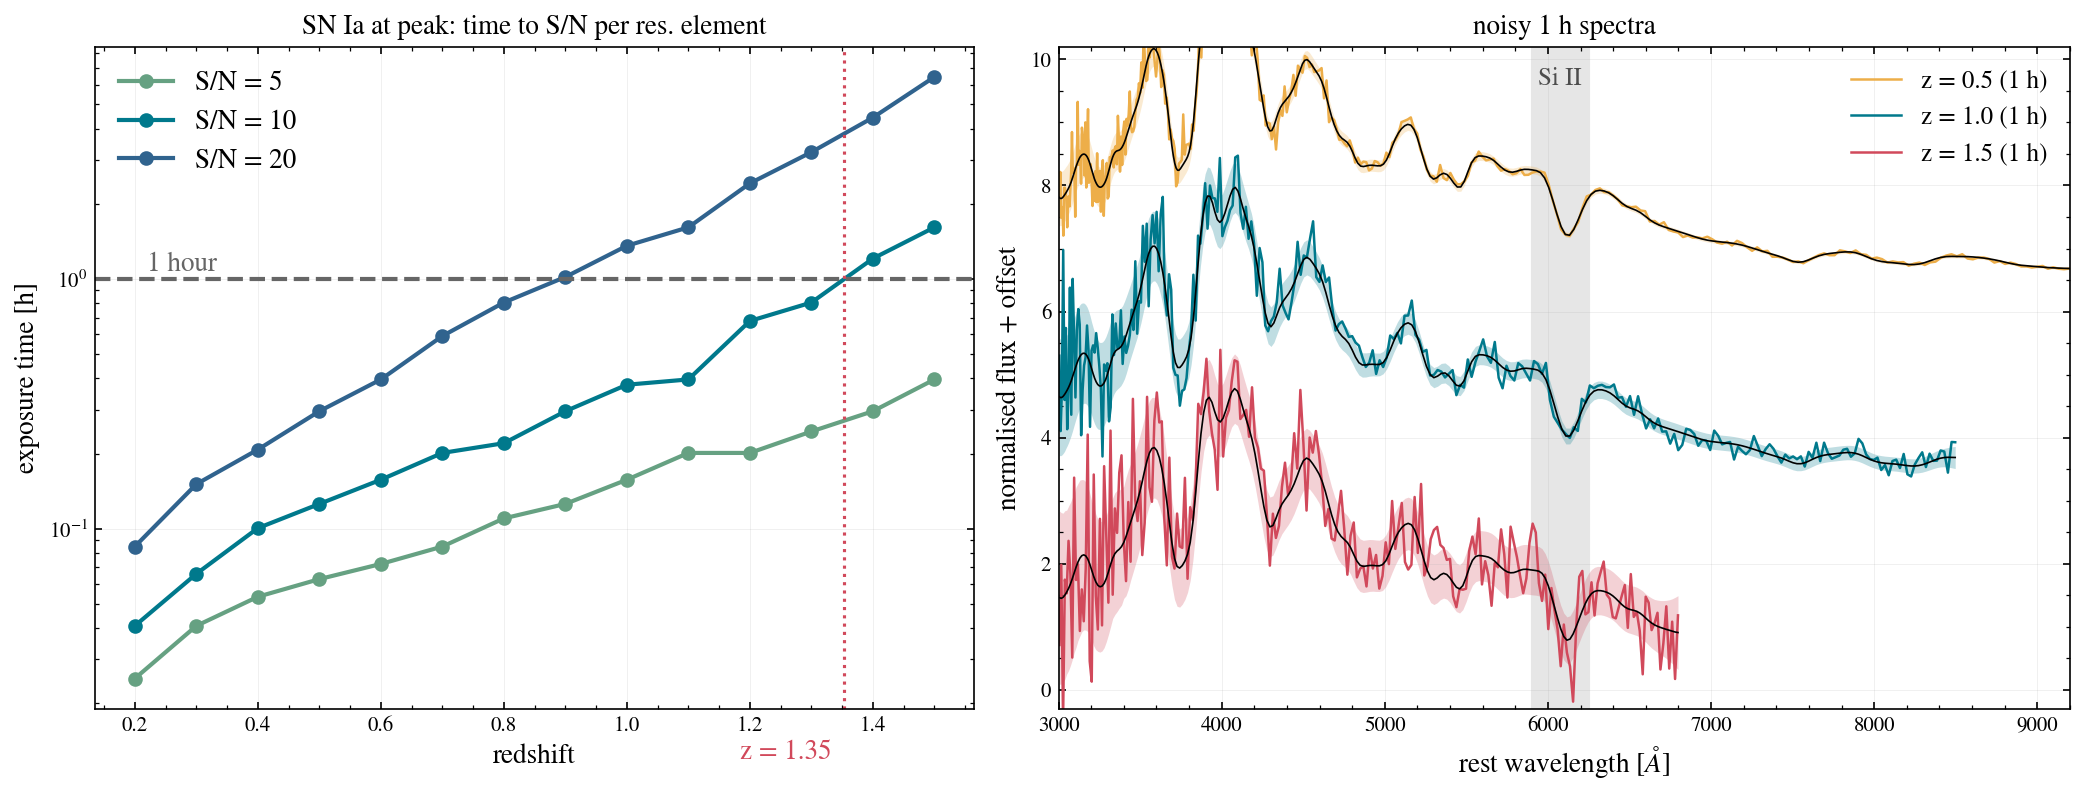

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1, 1.15]))
cols = {5: '#66a182', 10: '#00798c', 20: '#30638e'}
for s in SNRS:
    ax1.semilogy(Z, texp[s] / 3600, 'o-', color=cols[s], label=f'S/N = {s}')
ax1.axhline(1, color='0.4', ls='--')
ax1.text(0.22, 1.08, '1 hour', color='0.4', fontsize=13)
ax1.axvline(z_at(texp[10]), color='#d1495b', ls=':', lw=1.5)
ax1.text(z_at(texp[10]) - 0.02, 0.012, f'z = {z_at(texp[10]):.2f}', color='#d1495b', fontsize=13, ha='right')
ax1.set(xlabel='redshift', ylabel='exposure time [h]', title='SN Ia at peak: time to S/N per res. element')
ax1.legend(loc='upper left', fontsize=13)

for k, (z, (lr, f, f0, e)) in enumerate(examples.items()):
    m = (lr > 6000) & (lr < 6200)
    norm = np.median(f0[m])
    off = 3.2 * (2 - k)
    c = ['#edae49', '#00798c', '#d1495b'][k]
    ax2.fill_between(lr, (f0 - e) / norm + off, (f0 + e) / norm + off, color=c, alpha=0.25, lw=0)
    ax2.plot(lr, f / norm + off, color=c, lw=1.2, label=f'z = {z} (1 h)')
    ax2.plot(lr, f0 / norm + off, color='k', lw=0.8)
ax2.axvspan(5900, 6250, color='0.9', zorder=0)
ax2.text(6075, 9.6, 'Si II', ha='center', fontsize=12, color='0.3')
ax2.set(xlim=(3000, 9200), ylim=(-0.3, 10.2), xlabel=r'rest wavelength [$\AA$]', ylabel='normalised flux + offset',
        title='noisy 1 h spectra')
ax2.legend(loc='upper right', fontsize=12)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

For a normal SN Ia at peak ($x_1=0$, $c=0$, $M_B=-19.3$), Lazuli's IFS reaches a mean S/N = 10 per resolution element (rest 4000–6800 Å) in one hour out to **z ≈ 1.35** (fixed 1 h read-out: S/N drops below 10 at z ≈ 1.33). S/N = 20 in an hour holds to z ≈ 0.9, while S/N = 5 needs only ~24 min even at z = 1.5, the edge of the rest-frame window in the 1.7 µm bandpass.

## Caveats & next steps

- **Idealised extraction:** slicersim assumes the point-source spectrum is perfectly extracted from the cube (no host-galaxy subtraction, no extraction losses beyond the aperture). A real SN on its host will need the host model (`advanced_host_galaxy` tutorial), which raises the noise.
- **One SN template:** a normal SALT SN Ia ($x_1 = 0$, $c = 0$, $M_B = -19.3$) at exactly peak; reddened ($c > 0$) or fast-declining SNe, and phases a week past peak, need more time. The S/N criterion (mean S/N per resolution element over rest 4000–6800 Å) is a proxy for "classification quality", not a classifier. Beyond $z \approx 1.5$ the red end of that window leaves the 1.7 µm cut-off and the mean is taken over what is left.
- **Read-out quantisation:** `setup_to_snr` picks discrete MACC modes, so the curves step; overheads (slews, acquisition, dithers) are not included.
- **Ideas:** (1) swap to `model="twin"` or vary `c`, `x1`, `phase` to map the typing window around peak; (2) restrict the S/N window to Si II 6150 Å and ask how the classification redshift limit changes; (3) switch to the end-of-life throughput with `sn.change_configuration("eol")` and redo the curve.